# Goal

Here, I will go over the basics of the package. This includes some more detail on the input formats, how to define weights, and different scaling/stretch functions. 

# Imports

In [2]:
import sys
sys.path.append("..") #Point this to where the ensor.py file is located
from ensor import *

# Code

### Part 1: Open a fits file and load the bands you want to visualize
You might need to customize this to fit your own image. Just make sure each band is in nanomaggies (https://www.sdss3.org/dr8/algorithms/magnitudes.php). If your inputs are not in nanomaggies, this code comes with convenient functions that can help you convert units: `njy_to_nanomaggy`, `nanomaggy_to_njy`, `nanomaggy_to_mag`, `mag_to_nanomaggy`. In principle, this code should work with any linear flux units, but the default options for the parameters used in the various scaling/stretch functions might then need some more fine-tuning. 

We are also assuming that the images are already aligned etc. 

In [3]:
#Opening a fits file with gri bands. 
images_dir = '../data/'

fileloc = f'{images_dir}/Legacy/zoom_in.fits'

hdul = fits.open(fileloc)

g = hdul[0].data[0] #Units need to be in nanomaggy!
r = hdul[0].data[1]
z = hdul[0].data[2]

### Part 2: Play around with weights

The weights variable is a dictionary that maps all bands with their corresponding weight in the different RGB. channels. For each band, this should be a tuple with 3 elements, representing the weight in red, green, and blue channels.

The weights shown below are the Legacy/SDSS preset values. They basically map the g-band to blue channel, the r-band to the green channel, and the z-band to the red channel.

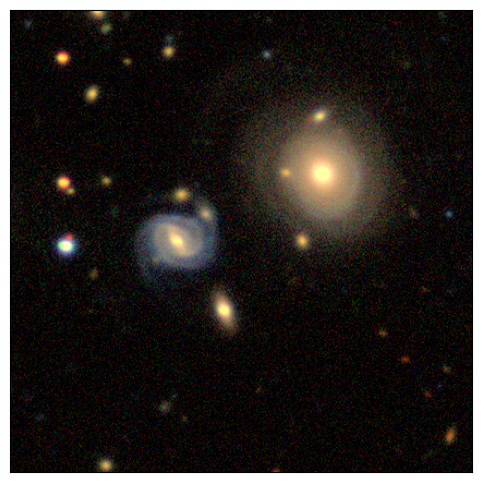

In [4]:
imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 0, 6.0), #r, g, b
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

rgb = make_image(imgs, bands, weights, func = asinh)
plot_image(rgb)

However, you can adjust them however you want, and e.g., give more weight to the g-band to make things look bluer. 

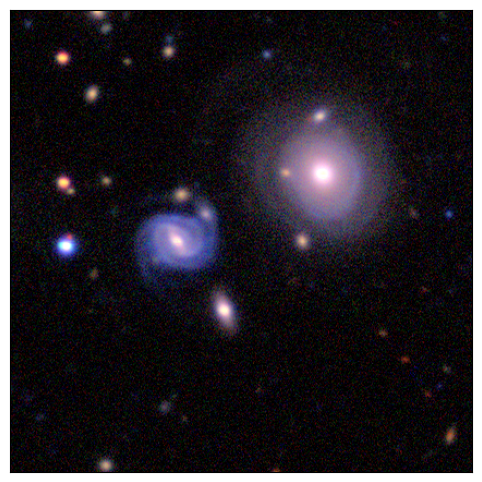

In [5]:
imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 0, 10.0), #r, g, b
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

rgb = make_image(imgs, bands, weights, func = asinh)
plot_image(rgb)

Or you can also make sure the g-band also contributes to the green channel. This is helpful if you e.g., have four bands, and want to combine two of them into one of the colour channels.

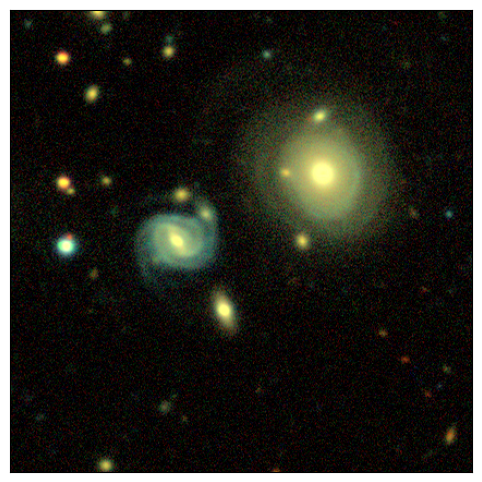

In [6]:
imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 2.0, 6.0), #r, g, b
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

rgb = make_image(imgs, bands, weights, func = asinh)
plot_image(rgb)

### Part 3: Different scaling/stretch functions

In order to create colour images, you need a function that maps flux values to a value between 0-1. This is called a scaling function, or a stretch function. This package comes with a few different built-in functions, which you can choose in `make_image` by changing the `func` argument.

In [7]:
# We are keeping the imgs, bands, and weights constant throughout this section for simplicity.

imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 0, 6.0), #r, g, b
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

For example, you can use a linear scaling function. This is generally not recommended though, as a linear function saturates bright cores of galaxies relatively quickly.

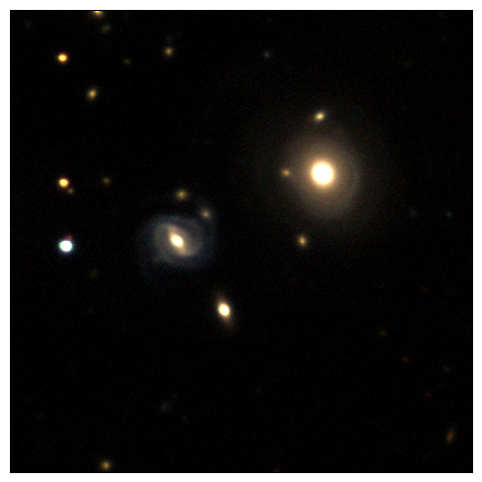

In [8]:
rgb = make_image(imgs, bands, weights, func = linear)
plot_image(rgb)

Alternatively, you can use the built-in sqrt, log, or MTF functions:

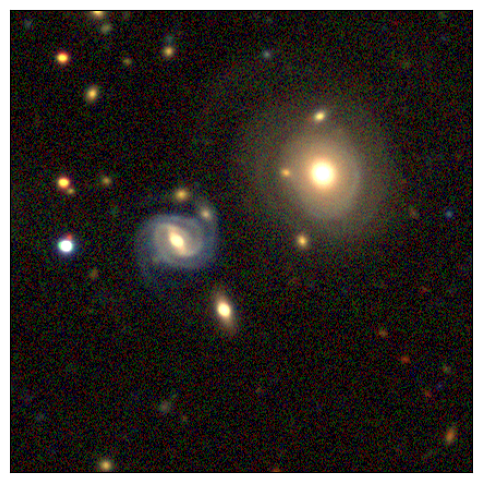

In [22]:
rgb = make_image(imgs, bands, weights, func = sqrt)
plot_image(rgb)

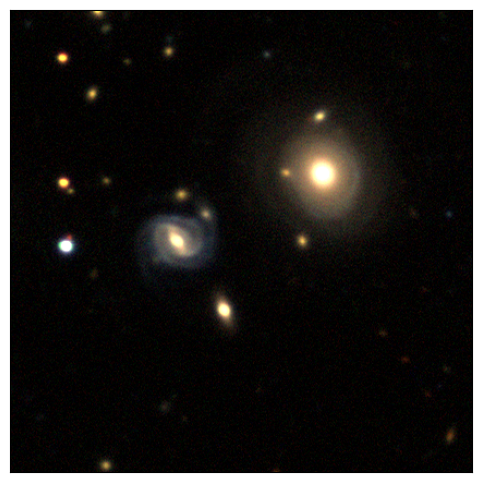

In [23]:
rgb = make_image(imgs, bands, weights, func = log)
plot_image(rgb)

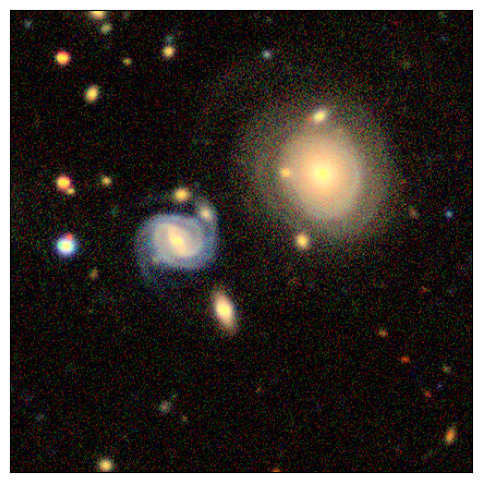

In [30]:
rgb = make_image(imgs, bands, weights, func = mtf_inverse)
plot_image(rgb)

However, my personal favourite is the asinh, as it really makes these fainter regions pop more:

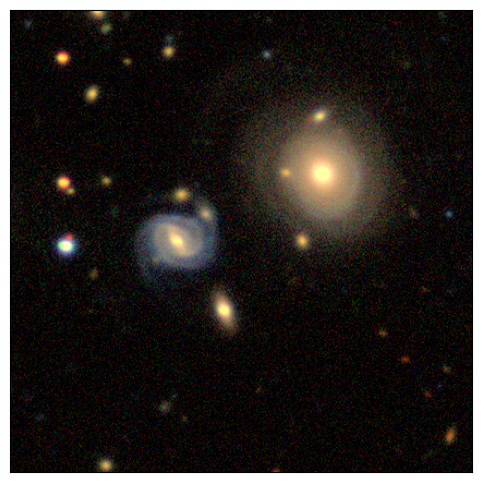

In [11]:
rgb = make_image(imgs, bands, weights, func = asinh)
plot_image(rgb)

Each of these parameters comes with tunable parameters. For example, for the asinh scale function, you have Q and stretch that you can adjust. You can enter these tunable parameters directly into `make_image`:

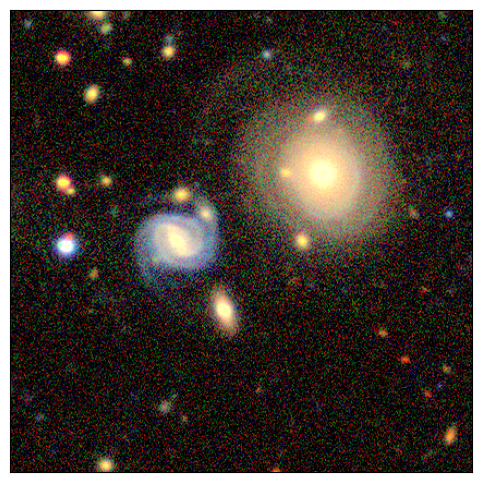

In [12]:
rgb = make_image(imgs, bands, weights, func = asinh, Q = 20, stretch = 3)
plot_image(rgb)

For more information on each of these scale functions, and to find out what their tunable parameters are, type e.g.,: help(asinh)

In [13]:
help(asinh)

Help on function asinh in module ensor:

asinh(x, Q=20, stretch=1, m=0)
    This is the Legacy Survey / SDSS parameterization, which I like a lot
    https://github.com/legacysurvey/legacypipe/blob/f77ed93c4e9df40e27aec132fd9a9db0c78678d5/py/legacypipe/survey.py#L492

    f(i) = asinh(Q * I) / sqrt(Q).
    Where I is img * stretch + m

    Q, stretch, and m are all tuneable parameters.

    Q dictates where transition happens from linear to log.
    As Q -> 0, there is no log part. Just linear.
    As Q increases, log part stays longer.

    Higher stretch helps faint features pop more, but also adds more noise.

    Note that the denominator above is sqrt(Q), instead of Q in traditional asinh. This sqrt() helps boost faint signals even more.
    This is because, in traditional asinh, where:
    f(i) = asinh(Q*I)/sqrt(Q), in linear regime: f(i) = Q*I/Q = I.

    Whereas now:
    f(i) = asinh(Q*I)/sqrt(Q), in linear regime: f(i) = Q*I/sqrt(Q) = I sqrt(Q). So boost upwards!



The cool thing about this is that each of these scalling functions are actually just python functions. This means that you can very easily define your own! Let's say, for example, let's say you want to define you own scaling function that is essentially a generalization of sqrt. You can then just define a new function, where one arugment is the input (e.g., x), and all the other arguments are tuneable parameters. The output of the function should be the transformed input. So, for example:

In [14]:
def root(x, n = 2):
    '''
    n is a tuneable parameter. If n == 2, then this is the same as sqrt. 
    '''
    return x**(1/n)

You can then now run `make_image`, where you pass `func=root` as one of the arguments. You can share any tuneable parameters as well, as follows:

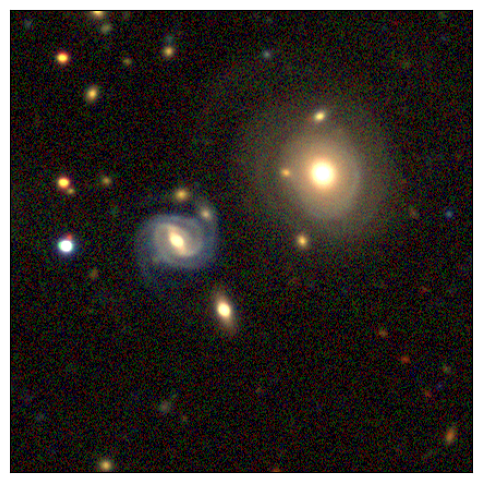

In [15]:
rgb = make_image(imgs, bands, weights, func = root, n = 2)
plot_image(rgb)

Let's now try to change the value of n... 

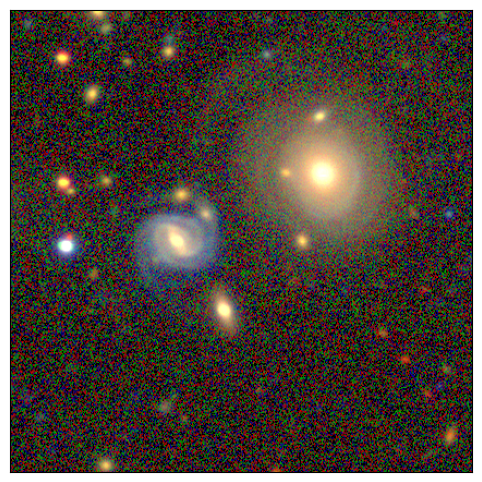

In [21]:
rgb = make_image(imgs, bands, weights, func = root, n = 3)
plot_image(rgb)

Et voilà!